In [0]:
# Install required packages
%pip install wordcloud matplotlib seaborn transformers torch nltk textblob vaderSentiment
!python -m nltk.downloader punkt stopwords


Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


I0000 00:00:1787518160.052149      74 fork_posix.cc:77] Other threads are currently calling into gRPC, skipping fork() handlers


<frozen runpy>:128: RuntimeWarning: 'nltk.downloader' found in sys.modules after import of package 'nltk', but prior to execution of 'nltk.downloader'; this may result in unpredictable behaviour
[nltk_data] Downloading package punkt to /home/spark-
[nltk_data]     fa161d45-d41d-4be7-ac44-d5/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /home/spark-
[nltk_data]     fa161d45-d41d-4be7-ac44-d5/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [0]:
%pip install --upgrade wordcloud
dbutils.library.restartPython()

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import numpy as np

class AdvancedWordCloud:
    def __init__(self, width=800, height=400):
        self.width = width
        self.height = height
        
    def generate_cloud(self, text, mask=None, colormap='viridis'):
        wordcloud = WordCloud(
            width=self.width,
            height=self.height,
            background_color='white',
            colormap=colormap,
            max_words=200,
            mask=mask,
            contour_width=3,
            contour_color='steelblue'
        ).generate(text)
        
        return wordcloud
    
    def plot_cloud(self, wordcloud, title="Word Cloud Visualization"):
        plt.figure(figsize=(15, 8))
        plt.imshow(wordcloud, interpolation='bilinear')
        plt.axis('off')
        plt.title(title)
        plt.show()


In [0]:
from transformers import pipeline
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from textblob import TextBlob

class ModernSentimentAnalyzer:
    def __init__(self):
        # Initialize different sentiment analyzers
        self.transformer_analyzer = pipeline("sentiment-analysis")
        self.vader_analyzer = SentimentIntensityAnalyzer()
        
    def analyze_with_transformers(self, text):
        """Analyze sentiment using transformer models"""
        result = self.transformer_analyzer(text)[0]
        return {
            'label': result['label'],
            'score': result['score']
        }
    
    def analyze_with_vader(self, text):
        """Analyze sentiment using VADER"""
        scores = self.vader_analyzer.polarity_scores(text)
        return {
            'compound': scores['compound'],
            'pos': scores['pos'],
            'neu': scores['neu'],
            'neg': scores['neg']
        }
    
    def analyze_with_textblob(self, text):
        """Analyze sentiment using TextBlob"""
        analysis = TextBlob(text)
        return {
            'polarity': analysis.sentiment.polarity,
            'subjectivity': analysis.sentiment.subjectivity
        }
        
    def comprehensive_analysis(self, text):
        """Perform sentiment analysis using all methods"""
        return {
            'transformer': self.analyze_with_transformers(text),
            'vader': self.analyze_with_vader(text),
            'textblob': self.analyze_with_textblob(text)
        }


/local_disk0/.ephemeral_nfs/envs/pythonEnv-fa161d45-d41d-4be7-ac44-d5283e98a6cd/lib/python3.12/site-packages/torch/_vmap_internals.py:9: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  from torch.utils._pytree import _broadcast_to_and_flatten, tree_flatten, tree_unflatten


In [0]:
class SentimentVisualizer:
    def __init__(self):
        self.analyzer = ModernSentimentAnalyzer()
        
    def plot_sentiment_distribution(self, texts):
        """Plot sentiment distribution for a collection of texts"""
        results = [self.analyzer.comprehensive_analysis(text) for text in texts]
        
        # Prepare data for plotting
        transformer_sentiments = [r['transformer']['label'] for r in results]
        vader_compounds = [r['vader']['compound'] for r in results]
        textblob_polarities = [r['textblob']['polarity'] for r in results]
        
        # Create visualization
        fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))
        
        # Transformer results
        sns.countplot(x=transformer_sentiments, ax=ax1)
        ax1.set_title('Transformer Sentiment Distribution')
        
        # VADER results
        sns.histplot(vader_compounds, ax=ax2, bins=20)
        ax2.set_title('VADER Compound Scores')
        
        # TextBlob results
        sns.histplot(textblob_polarities, ax=ax3, bins=20)
        ax3.set_title('TextBlob Polarity Scores')
        
        plt.tight_layout()
        plt.show()


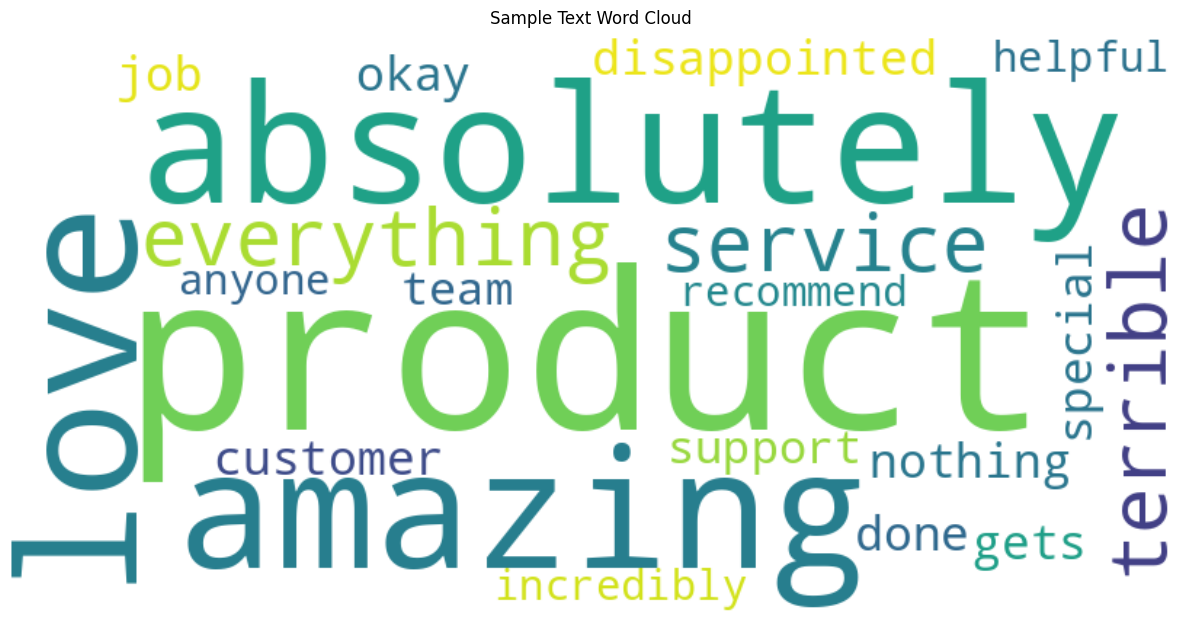

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]


Text: This product is absolutely amazing! I love everything about it.
Analysis Results:
Transformer: {'label': 'POSITIVE', 'score': 0.99988853931427}
VADER: {'compound': 0.8705, 'pos': 0.525, 'neu': 0.475, 'neg': 0.0}
TextBlob: {'polarity': 0.625, 'subjectivity': 0.75}

Text: The service was terrible and I'm very disappointed.
Analysis Results:
Transformer: {'label': 'NEGATIVE', 'score': 0.999754011631012}
VADER: {'compound': -0.7574, 'pos': 0.0, 'neu': 0.48, 'neg': 0.52}
TextBlob: {'polarity': -0.9875, 'subjectivity': 0.9875}

Text: It's an okay product, nothing special but gets the job done.
Analysis Results:
Transformer: {'label': 'POSITIVE', 'score': 0.9978154897689819}
VADER: {'compound': -0.0462, 'pos': 0.12, 'neu': 0.745, 'neg': 0.135}
TextBlob: {'polarity': 0.4285714285714286, 'subjectivity': 0.5357142857142857}


[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.



Text: The customer support team was incredibly helpful!
Analysis Results:
Transformer: {'label': 'POSITIVE', 'score': 0.999334990978241}
VADER: {'compound': 0.7257, 'pos': 0.549, 'neu': 0.451, 'neg': 0.0}
TextBlob: {'polarity': 1.0, 'subjectivity': 0.9}

Text: I wouldn't recommend this to anyone.
Analysis Results:
Transformer: {'label': 'POSITIVE', 'score': 0.6467341184616089}
VADER: {'compound': -0.2755, 'pos': 0.0, 'neu': 0.703, 'neg': 0.297}
TextBlob: {'polarity': 0.0, 'subjectivity': 0.0}


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

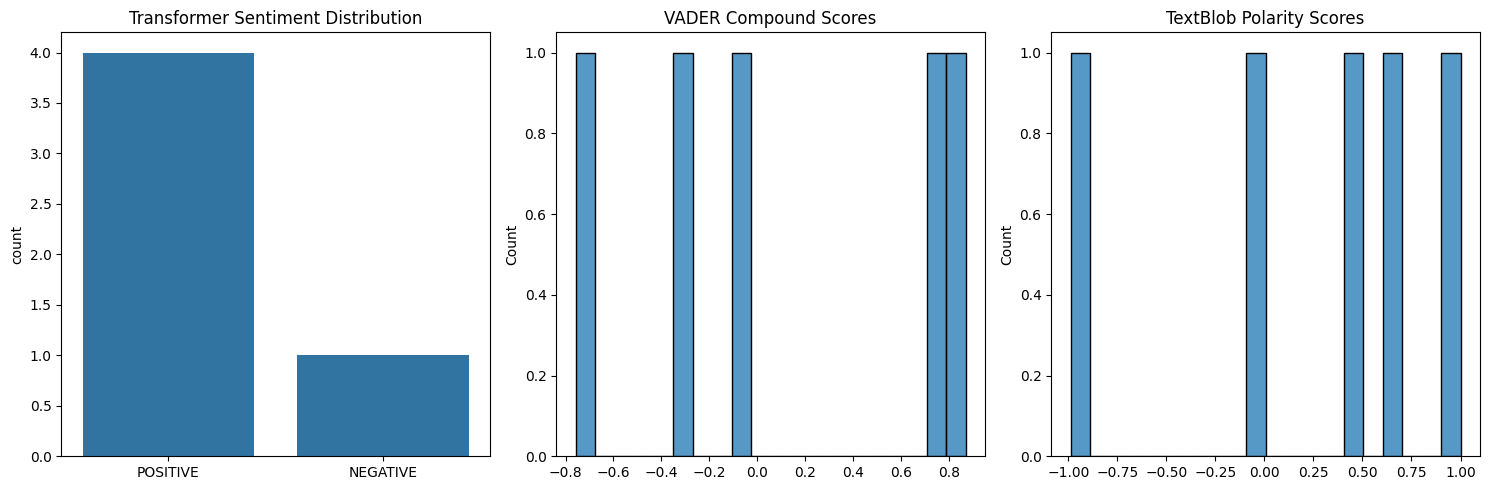

In [0]:
def main():
    # Sample text for analysis
    texts = [
        "This product is absolutely amazing! I love everything about it.",
        "The service was terrible and I'm very disappointed.",
        "It's an okay product, nothing special but gets the job done.",
        "The customer support team was incredibly helpful!",
        "I wouldn't recommend this to anyone."
    ]
    
    # Create WordCloud
    wordcloud = AdvancedWordCloud()
    cloud = wordcloud.generate_cloud(" ".join(texts))
    wordcloud.plot_cloud(cloud, "Sample Text Word Cloud")
    
    # Perform sentiment analysis
    analyzer = ModernSentimentAnalyzer()
    for text in texts:
        results = analyzer.comprehensive_analysis(text)
        print(f"\nText: {text}")
        print("Analysis Results:")
        print(f"Transformer: {results['transformer']}")
        print(f"VADER: {results['vader']}")
        print(f"TextBlob: {results['textblob']}")
    
    # Visualize results
    visualizer = SentimentVisualizer()
    visualizer.plot_sentiment_distribution(texts)

if __name__ == "__main__":
    main()
